In [4]:
import pandas as pd
import numpy as np

from sqlalchemy import create_engine, URL, text
import getpass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)
password = getpass.getpass("Enter PostgreSQL password: ")

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="olist_analysis"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("PostgreSQL connection successful!")


Enter PostgreSQL password:  ········


PostgreSQL connection successful!


In [5]:
tables = [
    "orders",
    "customers",
    "order_items",
    "products",
    "sellers",
    "payments",
    "reviews"
]

data = {}

for table in tables:
    data[table] = pd.read_sql_table(
        table,
        con=engine,
        schema="public"
    )

    print(
        f"{table}: "
        f"{data[table].shape[0]:,} rows × "
        f"{data[table].shape[1]} columns"
    )

orders: 99,441 rows × 8 columns
customers: 99,441 rows × 5 columns
order_items: 112,650 rows × 7 columns
products: 32,951 rows × 9 columns
sellers: 3,095 rows × 4 columns
payments: 103,886 rows × 5 columns
reviews: 99,224 rows × 7 columns


In [6]:
orders = data["orders"]
date_columns = [
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "order_delivered_customer_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

In [7]:
print("Total orders:", len(orders))

print(
    "Delivered orders:",
    (orders["order_status"] == "delivered").sum()
)

print(
    "Delivered orders missing required dates:",
    (
        (orders["order_status"] == "delivered") &
        orders[date_columns].isna().any(axis=1)
    ).sum()
)

Total orders: 99441
Delivered orders: 96478
Delivered orders missing required dates: 8


In [8]:
eligible_mask = (
    orders["order_status"].eq("delivered") &
    orders[date_columns].notna().all(axis=1)
)

modeling_base = orders.loc[eligible_mask].copy()

print("Eligible orders:", len(modeling_base))

Eligible orders: 96470


In [9]:
customers = data["customers"]
modeling_base = modeling_base.merge(
    customers,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Rows after customer merge:", len(modeling_base))
print("Missing customer states:", modeling_base["customer_state"].isna().sum())

Rows after customer merge: 96470
Missing customer states: 0


In [10]:
order_items = data["order_items"]
products = data["products"]
sellers = data["sellers"]
item_details = order_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

item_details = item_details.merge(
    sellers,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

In [11]:
item_details = item_details[
    item_details["order_id"].isin(modeling_base["order_id"])
].copy()

In [12]:
def get_mode(series):
    modes = series.mode(dropna=True)

    if len(modes) == 0:
        return np.nan

    return modes.iloc[0]

In [13]:
order_aggregates = (
    item_details
    .groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        seller_count=("seller_id", "nunique"),
        main_category=("product_category_name", get_mode),
        main_seller_state=("seller_state", get_mode)
    )
    .reset_index()
)

In [14]:
modeling_base = modeling_base.merge(
    order_aggregates,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Final modeling dataset shape:", modeling_base.shape)

Final modeling dataset shape: (96470, 18)


In [15]:
print("Number of rows:", len(modeling_base))

print(
    "Unique orders:",
    modeling_base["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    modeling_base["order_id"].duplicated().sum()
)

print("\nMissing values:")
print(modeling_base.isna().sum())

print("\nDataset information:")
modeling_base.info()

Number of rows: 96470
Unique orders: 96470
Duplicate order IDs: 0

Missing values:
order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
customer_unique_id                0
customer_zip_code_prefix          0
customer_city                     0
customer_state                    0
item_count                        0
total_price                       0
total_freight                     0
seller_count                      0
main_category                     0
main_seller_state                 0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  ----- 

In [16]:
modeling_df = modeling_base.copy()

purchase_date = modeling_df["order_purchase_timestamp"]

# Extract purchase-time features
modeling_df["purchase_hour"] = purchase_date.dt.hour

modeling_df["purchase_day"] = purchase_date.dt.day

modeling_df["purchase_weekday"] = purchase_date.dt.day_name()

modeling_df["purchase_month"] = purchase_date.dt.month_name()

modeling_df["purchase_quarter"] = purchase_date.dt.quarter

# Weekend indicator: Saturday = 5, Sunday = 6
modeling_df["purchase_is_weekend"] = (
    purchase_date.dt.dayofweek >= 5
).astype(int)

In [17]:
modeling_df["estimated_delivery_days"] = (
    modeling_df["order_estimated_delivery_date"] -
    modeling_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

In [18]:
modeling_df["estimated_delivery_days"].describe()

count   96470.00
mean       23.74
std         8.76
min         2.01
25%        18.33
50%        23.23
75%        28.41
max       155.14
Name: estimated_delivery_days, dtype: float64

In [19]:
modeling_df["same_state"] = (
    modeling_df["customer_state"] ==
    modeling_df["main_seller_state"]
).astype(int)

In [20]:
numerical_features = [
    "purchase_hour",
    "purchase_day",
    "purchase_quarter",
    "purchase_is_weekend",
    "estimated_delivery_days",
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "same_state"
]

modeling_df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
purchase_hour,96470.00,14.77,5.33,0.00,11.00,15.00,19.00,23.00
purchase_day,96470.00,15.52,8.67,1.00,8.00,16.00,23.00,31.00
purchase_quarter,96470.00,2.35,1.06,1.00,1.00,2.00,3.00,4.00
purchase_is_weekend,96470.00,0.23,0.42,0.00,0.00,0.00,0.00,1.00
estimated_delivery_days,96470.00,23.74,8.76,2.01,18.33,23.23,28.41,155.14
item_count,96470.00,1.14,0.54,1.00,1.00,1.00,1.00,21.00
total_price,96470.00,137.04,209.05,0.85,45.90,86.50,149.90,13440.00
total_freight,96470.00,22.79,21.56,0.00,13.85,17.17,24.02,1794.96
seller_count,96470.00,1.01,0.12,1.00,1.00,1.00,1.00,5.00
same_state,96470.00,0.36,0.48,0.00,0.00,0.00,1.00,1.00


In [21]:
categorical_features = [
    "purchase_weekday",
    "purchase_month",
    "main_category",
    "customer_state",
    "main_seller_state"
]

modeling_df[categorical_features].describe().T

,count,unique,top,freq
purchase_weekday,96470,7,Monday,15701
purchase_month,96470,12,August,10544
main_category,96470,74,"Bed, Bath & Table",9239
customer_state,96470,27,SP,40494
main_seller_state,96470,22,SP,68261


In [22]:
for column in categorical_features:
    print(f"\n{column}")
    print(modeling_df[column].value_counts(dropna=False).head(10))


purchase_weekday
purchase_weekday
Monday       15701
Tuesday      15502
Wednesday    15074
Thursday     14322
Friday       13684
Sunday       11632
Saturday     10555
Name: count, dtype: int64

purchase_month
purchase_month
August      10544
May         10294
July        10028
March        9549
June         9231
April        9101
February     8208
January      7819
November     7288
December     5514
Name: count, dtype: int64

main_category
main_category
Bed, Bath & Table          9239
Health & Beauty            8622
Sports & Leisure           7477
Computers & Accessories    6519
Furniture & Decor          6209
Home Utilities             5670
Watches & Gifts            5453
Telephony                  4071
Automotive                 3803
Toys                       3758
Name: count, dtype: int64

customer_state
customer_state
SP    40494
RJ    12350
MG    11354
RS     5344
PR     4923
SC     3546
BA     3256
DF     2080
ES     1995
GO     1957
Name: count, dtype: int64

main_seller_stat

In [23]:
feature_columns = numerical_features + categorical_features

X = modeling_df[feature_columns].copy()

print("Feature matrix shape:", X.shape)

X.head()

Feature matrix shape: (96470, 15)


,purchase_hour,purchase_day,purchase_quarter,purchase_is_weekend,estimated_delivery_days,item_count,total_price,total_freight,seller_count,same_state,purchase_weekday,purchase_month,main_category,customer_state,main_seller_state
0,10,2,4,0,15.54,1,29.99,8.72,1,1,Monday,October,Home Utilities,SP,SP
1,20,24,3,0,19.14,1,118.70,22.76,1,0,Tuesday,July,Perfumes & Fragrances,BA,SP
2,8,8,3,0,26.64,1,159.90,19.22,1,0,Wednesday,August,Automotive,GO,SP
3,19,18,4,1,26.19,1,45.00,27.20,1,0,Saturday,November,Pet Shop,RN,MG
4,21,13,1,0,12.11,1,19.90,8.72,1,1,Tuesday,February,Stationery,SP,SP


In [24]:
print("Number of orders:", len(modeling_df))
print("Number of features:", len(feature_columns))

print("\nMissing values:")
print(X.isna().sum())

print("\nDuplicate order IDs:")
print(modeling_df["order_id"].duplicated().sum())

print("\nFeature data types:")
print(X.dtypes)


Number of orders: 96470
Number of features: 15

Missing values:
purchase_hour              0
purchase_day               0
purchase_quarter           0
purchase_is_weekend        0
estimated_delivery_days    0
item_count                 0
total_price                0
total_freight              0
seller_count               0
same_state                 0
purchase_weekday           0
purchase_month             0
main_category              0
customer_state             0
main_seller_state          0
dtype: int64

Duplicate order IDs:
0

Feature data types:
purchase_hour                int32
purchase_day                 int32
purchase_quarter             int32
purchase_is_weekend          int64
estimated_delivery_days    float64
item_count                   int64
total_price                float64
total_freight              float64
seller_count                 int64
same_state                   int64
purchase_weekday            object
purchase_month              object
main_category          

In [25]:
modeling_df["late_delivery"] = (
    modeling_df["order_delivered_customer_date"] >
    modeling_df["order_estimated_delivery_date"]
).astype(int)


In [26]:
modeling_df["late_delivery"].value_counts()

late_delivery
0    88644
1     7826
Name: count, dtype: int64

In [27]:
modeling_df["late_delivery"].value_counts(normalize=True) * 100

late_delivery
0   91.89
1    8.11
Name: proportion, dtype: float64

In [28]:
print(modeling_df["late_delivery"].value_counts())

print(
    modeling_df["late_delivery"]
    .value_counts(normalize=True) * 100
)

print(
    modeling_df.groupby("late_delivery")[
        ["total_price", "total_freight", "item_count",
         "estimated_delivery_days"]
    ].mean()
)

late_delivery
0    88644
1     7826
Name: count, dtype: int64
late_delivery
0   91.89
1    8.11
Name: proportion, dtype: float64
               total_price  total_freight  item_count  estimated_delivery_days
late_delivery                                                                 
0                   136.06          22.62        1.14                    23.89
1                   148.09          24.62        1.11                    21.97


In [29]:
comparison = modeling_df.groupby("late_delivery").agg(
    total_orders=("order_id", "count"),
    avg_price=("total_price", "mean"),
    median_price=("total_price", "median"),
    avg_freight=("total_freight", "mean"),
    median_freight=("total_freight", "median"),
    avg_items=("item_count", "mean"),
    avg_estimated_days=("estimated_delivery_days", "mean"),
    median_estimated_days=("estimated_delivery_days", "median")
)

comparison

,total_orders,avg_price,median_price,avg_freight,median_freight,avg_items,avg_estimated_days,median_estimated_days
late_delivery,,,,,,,,
0,88644,136.06,85.50,22.62,17.07,1.14,23.89,23.30
1,7826,148.09,89.90,24.62,18.05,1.11,21.97,22.22


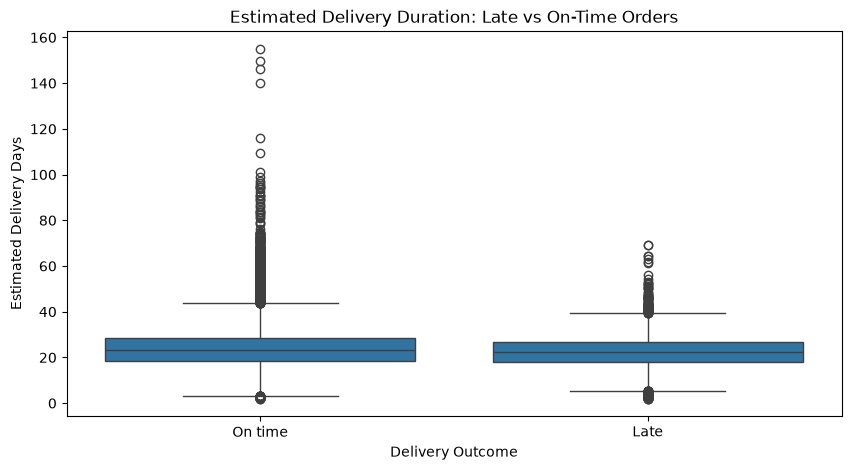

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=modeling_df,
    x="late_delivery",
    y="estimated_delivery_days"
)

plt.xticks([0, 1], ["On time", "Late"])
plt.title("Estimated Delivery Duration: Late vs On-Time Orders")
plt.xlabel("Delivery Outcome")
plt.ylabel("Estimated Delivery Days")

plt.show()

In [31]:
# Target distribution
print(modeling_df["late_delivery"].value_counts())

print("\nTarget percentages:")
print(
    modeling_df["late_delivery"]
    .value_counts(normalize=True) * 100
)

# Check for missing predictor values
print("\nMissing feature values:")
print(X.isna().sum())

# Check for duplicate orders
print("\nDuplicate orders:")
print(modeling_df["order_id"].duplicated().sum())

late_delivery
0    88644
1     7826
Name: count, dtype: int64

Target percentages:
late_delivery
0   91.89
1    8.11
Name: proportion, dtype: float64

Missing feature values:
purchase_hour              0
purchase_day               0
purchase_quarter           0
purchase_is_weekend        0
estimated_delivery_days    0
item_count                 0
total_price                0
total_freight              0
seller_count               0
same_state                 0
purchase_weekday           0
purchase_month             0
main_category              0
customer_state             0
main_seller_state          0
dtype: int64

Duplicate orders:
0


In [32]:
feature_columns = [
    "purchase_hour",
    "purchase_day",
    "purchase_weekday",
    "purchase_month",
    "purchase_quarter",
    "purchase_is_weekend",
    "estimated_delivery_days",
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "main_category",
    "customer_state",
    "main_seller_state",
    "same_state"
]

X = modeling_df[feature_columns].copy()

y = modeling_df["late_delivery"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96470, 15)
y shape: (96470,)


In [33]:
# Sort orders chronologically
modeling_df = modeling_df.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Reconstruct X and y after sorting
X = modeling_df[feature_columns].copy()
y = modeling_df["late_delivery"].copy()

# Determine the chronological cutoff
split_index = int(len(modeling_df) * 0.80)

# Split into training and testing sets
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (77176, 15)
Testing set: (19294, 15)


In [34]:
print("Training period:")
print(
    modeling_df.iloc[:split_index]["order_purchase_timestamp"].min(),
    "to",
    modeling_df.iloc[:split_index]["order_purchase_timestamp"].max()
)

print("\nTesting period:")
print(
    modeling_df.iloc[split_index:]["order_purchase_timestamp"].min(),
    "to",
    modeling_df.iloc[split_index:]["order_purchase_timestamp"].max()
)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training period:
2016-09-15 12:16:38 to 2018-05-26 18:16:57

Testing period:
2018-05-26 18:18:03 to 2018-08-29 15:00:37

Training target distribution:
late_delivery
0   91.18
1    8.82
Name: proportion, dtype: float64

Testing target distribution:
late_delivery
0   94.71
1    5.29
Name: proportion, dtype: float64


In [35]:
numerical_features = [
    "purchase_hour",
    "purchase_day",
    "purchase_quarter",
    "purchase_is_weekend",
    "estimated_delivery_days",
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "same_state"
]

categorical_features = [
    "purchase_weekday",
    "purchase_month",
    "main_category",
    "customer_state",
    "main_seller_state"
]

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [37]:
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [38]:
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [40]:
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)


In [41]:
print("X_train column types:")
print(X_train.columns.map(type).value_counts())

print("\nX_test column types:")
print(X_test.columns.map(type).value_counts())

print("\nNon-string training columns:")
print([(repr(col), type(col)) for col in X_train.columns if not isinstance(col, str)])

print("\nNon-string testing columns:")
print([(repr(col), type(col)) for col in X_test.columns if not isinstance(col, str)])

X_train column types:
<class 'str'>                                    14
<class 'sqlalchemy.sql.elements.quoted_name'>     1
Name: count, dtype: int64

X_test column types:
<class 'str'>                                    14
<class 'sqlalchemy.sql.elements.quoted_name'>     1
Name: count, dtype: int64

Non-string training columns:
[]

Non-string testing columns:
[]


In [42]:
# Normalize column names in the source DataFrame
modeling_df.columns = [str(col) for col in modeling_df.columns]

# Normalize feature lists
numerical_features = [str(col) for col in numerical_features]
categorical_features = [str(col) for col in categorical_features]
feature_columns = numerical_features + categorical_features

# Recreate X and y
X = modeling_df[feature_columns].copy()
y = modeling_df["late_delivery"].copy()

# Recreate the chronological split
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Force plain string column names
X_train.columns = [str(col) for col in X_train.columns]
X_test.columns = [str(col) for col in X_test.columns]

In [43]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (77176, 152)
Testing shape: (19294, 152)


In [44]:
monthly_late_rate = (
    modeling_df
    .set_index("order_purchase_timestamp")
    .resample("ME")["late_delivery"]
    .agg(["count", "sum", "mean"])
)

monthly_late_rate["late_percentage"] = (
    monthly_late_rate["mean"] * 100
)

monthly_late_rate

,count,sum,mean,late_percentage
order_purchase_timestamp,,,,
2016-09-30,1,1,1.00,100.00
2016-10-31,265,3,0.01,1.13
2016-11-30,0,0,NaN,NaN
2016-12-31,1,0,0.00,0.00
2017-01-31,750,23,0.03,3.07
2017-02-28,1653,53,0.03,3.21
2017-03-31,2546,142,0.06,5.58
2017-04-30,2303,181,0.08,7.86
2017-05-31,3545,128,0.04,3.61


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

In [46]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [47]:
y_pred_lr = lr_model.predict(X_test_processed)

In [48]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["On Time", "Late"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.9471338239867316

Classification Report:
              precision    recall  f1-score   support

     On Time       0.95      1.00      0.97     18273
        Late       0.60      0.00      0.01      1021

    accuracy                           0.95     19294
   macro avg       0.77      0.50      0.49     19294
weighted avg       0.93      0.95      0.92     19294


Confusion Matrix:
[[18271     2]
 [ 1018     3]]


In [49]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_balanced.fit(X_train_processed, y_train)

y_pred_balanced = lr_balanced.predict(X_test_processed)

In [50]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["On Time", "Late"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Accuracy: 0.8543070384575515

Classification Report:
              precision    recall  f1-score   support

     On Time       0.95      0.89      0.92     18273
        Late       0.10      0.22      0.14      1021

    accuracy                           0.85     19294
   macro avg       0.53      0.56      0.53     19294
weighted avg       0.91      0.85      0.88     19294


Confusion Matrix:
[[16258  2015]
 [  796   225]]


In [51]:
y_prob_balanced = lr_balanced.predict_proba(X_test_processed)[:, 1]

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_balanced >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Late Precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "Late Recall": recall_score(y_test, y_pred_threshold, zero_division=0),
        "Late F1": f1_score(y_test, y_pred_threshold, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Accuracy,Late Precision,Late Recall,Late F1
0,0.30,0.59,0.09,0.77,0.17
1,0.40,0.77,0.10,0.42,0.16
2,0.50,0.85,0.10,0.22,0.14
3,0.60,0.91,0.13,0.13,0.13
4,0.70,0.94,0.20,0.06,0.09


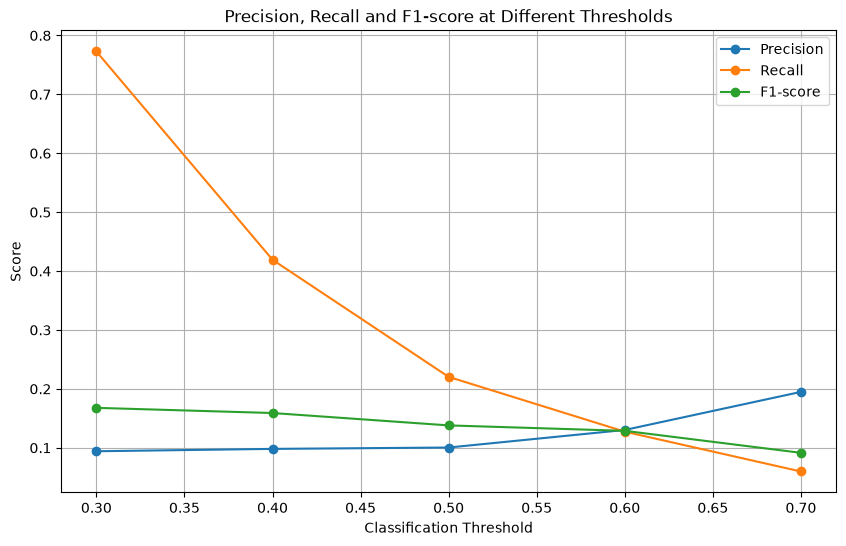

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Late Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Late Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Late F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score at Different Thresholds")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
# Split the existing training data chronologically

inner_split_index = int(len(X_train) * 0.75)

X_inner_train = X_train.iloc[:inner_split_index].copy()
X_validation = X_train.iloc[inner_split_index:].copy()

y_inner_train = y_train.iloc[:inner_split_index].copy()
y_validation = y_train.iloc[inner_split_index:].copy()

print("Inner training set:", X_inner_train.shape)
print("Validation set:", X_validation.shape)
print("Final test set:", X_test.shape)

Inner training set: (57882, 15)
Validation set: (19294, 15)
Final test set: (19294, 15)


In [55]:
print("Inner training target distribution:")
print(y_inner_train.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_validation.value_counts(normalize=True).round(3))

Inner training target distribution:
late_delivery
0   0.92
1   0.08
Name: proportion, dtype: float64

Validation target distribution:
late_delivery
0   0.88
1   0.12
Name: proportion, dtype: float64


In [56]:
from sklearn.base import clone

validation_preprocessor = clone(preprocessor)

X_inner_train_processed = validation_preprocessor.fit_transform(
    X_inner_train
)

X_validation_processed = validation_preprocessor.transform(
    X_validation
)

print("Inner training matrix:", X_inner_train_processed.shape)
print("Validation matrix:", X_validation_processed.shape)

Inner training matrix: (57882, 151)
Validation matrix: (19294, 151)


In [57]:
from sklearn.linear_model import LogisticRegression

lr_validation = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_validation.fit(
    X_inner_train_processed,
    y_inner_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [58]:
y_prob_validation = lr_validation.predict_proba(
    X_validation_processed
)[:, 1]

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_validation >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_validation, y_pred_threshold
        ),
        "Late Precision": precision_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late Recall": recall_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late F1": f1_score(
            y_validation, y_pred_threshold, zero_division=0
        )
    })

validation_results = pd.DataFrame(results)

validation_results.round(3)

,Threshold,Accuracy,Late Precision,Late Recall,Late F1
0,0.10,0.13,0.12,1.00,0.21
1,0.20,0.20,0.12,0.98,0.22
2,0.30,0.33,0.14,0.92,0.24
3,0.40,0.47,0.16,0.82,0.27
4,0.50,0.63,0.19,0.66,0.29
5,0.60,0.77,0.24,0.46,0.32
6,0.70,0.85,0.32,0.28,0.30
7,0.80,0.88,0.39,0.10,0.16
8,0.90,0.88,0.35,0.01,0.02


In [60]:
pr_auc_validation = average_precision_score(
    y_validation,
    y_prob_validation
)

print("Validation Average Precision:", round(pr_auc_validation, 4))

Validation Average Precision: 0.2504


In [61]:
# Transform the untouched test set
X_test_val_processed = validation_preprocessor.transform(X_test)

# Get predicted probabilities
y_prob_test = lr_validation.predict_proba(X_test_val_processed)[:, 1]

# Apply the threshold selected using validation data
selected_threshold = 0.60

y_pred_test = (y_prob_test >= selected_threshold).astype(int)

# Evaluate
print("Selected threshold:", selected_threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print("Late precision:", precision_score(y_test, y_pred_test, zero_division=0))
print("Late recall:", recall_score(y_test, y_pred_test, zero_division=0))
print("Late F1:", f1_score(y_test, y_pred_test, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

print("\nAverage Precision (PR-AUC):",
      average_precision_score(y_test, y_prob_test))

Selected threshold: 0.6
Accuracy: 0.9128744687467607
Late precision: 0.12155963302752294
Late recall: 0.10381978452497552
Late F1: 0.11199154780771263

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95     18273
           1       0.12      0.10      0.11      1021

    accuracy                           0.91     19294
   macro avg       0.54      0.53      0.53     19294
weighted avg       0.91      0.91      0.91     19294


Confusion Matrix:
[[17507   766]
 [  915   106]]

Average Precision (PR-AUC): 0.10458434185086381


In [62]:
# Identify the chronological split boundaries

print("Original training period:")
print(modeling_df.iloc[0]["order_purchase_timestamp"])
print(modeling_df.iloc[split_index - 1]["order_purchase_timestamp"])

print("\nOriginal test period:")
print(modeling_df.iloc[split_index]["order_purchase_timestamp"])
print(modeling_df.iloc[-1]["order_purchase_timestamp"])

Original training period:
2016-09-15 12:16:38
2018-05-26 18:16:57

Original test period:
2018-05-26 18:18:03
2018-08-29 15:00:37


In [63]:
print("Inner training period:")
print(modeling_df.loc[X_inner_train.index, "order_purchase_timestamp"].min())
print(modeling_df.loc[X_inner_train.index, "order_purchase_timestamp"].max())

print("\nValidation period:")
print(modeling_df.loc[X_validation.index, "order_purchase_timestamp"].min())
print(modeling_df.loc[X_validation.index, "order_purchase_timestamp"].max())

Inner training period:
2016-09-15 12:16:38
2018-03-03 10:06:23

Validation period:
2018-03-03 10:08:51
2018-05-26 18:16:57


In [64]:
# Define the chronological boundaries
inner_train_end = pd.Timestamp("2018-03-03 10:06:23")
original_train_end = pd.Timestamp("2018-05-26 18:16:57")

# Assign each order to its respective period
timestamps = modeling_df["order_purchase_timestamp"]

inner_train_mask = timestamps <= inner_train_end

validation_mask = (
    (timestamps > inner_train_end) &
    (timestamps <= original_train_end)
)

test_mask = timestamps > original_train_end

# Calculate statistics
periods = {
    "Inner Training": inner_train_mask,
    "Validation": validation_mask,
    "Test": test_mask
}

period_results = []

for period_name, mask in periods.items():
    period_data = modeling_df.loc[mask]

    period_results.append({
        "Period": period_name,
        "Orders": len(period_data),
        "Late Orders": period_data["late_delivery"].sum(),
        "On-Time Orders": (period_data["late_delivery"] == 0).sum(),
        "Late Rate (%)": period_data["late_delivery"].mean() * 100
    })

period_summary = pd.DataFrame(period_results)

period_summary.round(2)

,Period,Orders,Late Orders,On-Time Orders,Late Rate (%)
0,Inner Training,57882,4563,53319,7.88
1,Validation,19294,2242,17052,11.62
2,Test,19294,1021,18273,5.29


In [65]:
# Create a test evaluation DataFrame
test_evaluation = modeling_df.loc[
    X_test.index,
    ["order_purchase_timestamp", "late_delivery"]
].copy()

test_evaluation["predicted_probability"] = y_prob_test
test_evaluation["predicted_late"] = y_pred_test

test_evaluation["month"] = (
    test_evaluation["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly performance
monthly_model_performance = (
    test_evaluation
    .groupby("month")
    .apply(
        lambda group: pd.Series({
            "Orders": len(group),
            "Actual Late Orders": group["late_delivery"].sum(),
            "Actual Late Rate (%)": group["late_delivery"].mean() * 100,
            "Predicted Late Orders": group["predicted_late"].sum(),
            "Precision": precision_score(
                group["late_delivery"],
                group["predicted_late"],
                zero_division=0
            ),
            "Recall": recall_score(
                group["late_delivery"],
                group["predicted_late"],
                zero_division=0
            )
        }),
        include_groups=False
    )
    .reset_index()
)

monthly_model_performance.round(3)

,month,Orders,Actual Late Orders,Actual Late Rate (%),Predicted Late Orders,Precision,Recall
0,2018-05,691.00,2.00,0.29,1.00,0.00,0.00
1,2018-06,6096.00,83.00,1.36,106.00,0.07,0.08
2,2018-07,6156.00,276.00,4.48,389.00,0.13,0.18
3,2018-08,6351.00,660.00,10.39,376.00,0.13,0.08


In [83]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_inner_train_processed, y_inner_train)
print("UwU")

UwU


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict probabilities
y_prob_rf_val = rf_model.predict_proba(X_validation_processed)[:, 1]

# Initial threshold
y_pred_rf_val = (y_prob_rf_val >= 0.5).astype(int)

print("Random Forest - Validation Results")
print("Accuracy:", accuracy_score(y_validation, y_pred_rf_val))
print("Late Precision:", precision_score(y_validation, y_pred_rf_val, zero_division=0))
print("Late Recall:", recall_score(y_validation, y_pred_rf_val, zero_division=0))
print("Late F1:", f1_score(y_validation, y_pred_rf_val, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_validation, y_pred_rf_val, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_validation, y_pred_rf_val))

print("\nAverage Precision (PR-AUC):",
      average_precision_score(y_validation, y_prob_rf_val))

Random Forest - Validation Results
Accuracy: 0.8463252824712346
Late Precision: 0.2874779541446208
Late Recall: 0.21810883140053525
Late F1: 0.248034491503931

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.91     17052
           1       0.29      0.22      0.25      2242

    accuracy                           0.85     19294
   macro avg       0.59      0.57      0.58     19294
weighted avg       0.83      0.85      0.84     19294


Confusion Matrix:
[[15840  1212]
 [ 1753   489]]

Average Precision (PR-AUC): 0.21973579053200704


In [68]:
thresholds = np.arange(0.1, 1.0, 0.1)

rf_threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_rf_val >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_validation, y_pred_threshold),
        "Late Precision": precision_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late Recall": recall_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late F1": f1_score(
            y_validation, y_pred_threshold, zero_division=0
        )
    })

rf_threshold_results = pd.DataFrame(rf_threshold_results)

rf_threshold_results.round(3)

,Threshold,Accuracy,Late Precision,Late Recall,Late F1
0,0.10,0.12,0.12,1.00,0.21
1,0.20,0.19,0.12,0.96,0.21
2,0.30,0.40,0.14,0.81,0.24
3,0.40,0.69,0.20,0.52,0.28
4,0.50,0.85,0.29,0.22,0.25
5,0.60,0.88,0.39,0.04,0.08
6,0.70,0.88,0.38,0.00,0.00
7,0.80,0.88,0.00,0.00,0.00
8,0.90,0.88,0.00,0.00,0.00


In [69]:
selected_threshold = 0.40

# Transform the test data using the preprocessor fitted on inner training data
X_test_processed = validation_preprocessor.transform(X_test)

# Predict probabilities
y_prob_rf_test = rf_model.predict_proba(X_test_processed)[:, 1]

# Apply the selected threshold
y_pred_rf_test = (y_prob_rf_test >= selected_threshold).astype(int)
print("UwU")

UwU


In [70]:
print("Random Forest - Test Set Results")
print("---------------------------------")

print("Threshold:", selected_threshold)

print("Accuracy:", accuracy_score(y_test, y_pred_rf_test))

print("Late Precision:",
      precision_score(y_test, y_pred_rf_test, zero_division=0))

print("Late Recall:",
      recall_score(y_test, y_pred_rf_test, zero_division=0))

print("Late F1:",
      f1_score(y_test, y_pred_rf_test, zero_division=0))

print("Average Precision (PR-AUC):",
      average_precision_score(y_test, y_prob_rf_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_test))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_test))

Random Forest - Test Set Results
---------------------------------
Threshold: 0.4
Accuracy: 0.8983103555509485
Late Precision: 0.10228233305156383
Late Recall: 0.11851126346718903
Late F1: 0.10980036297640654
Average Precision (PR-AUC): 0.09756912895633471

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95     18273
           1       0.10      0.12      0.11      1021

    accuracy                           0.90     19294
   macro avg       0.53      0.53      0.53     19294
weighted avg       0.91      0.90      0.90     19294

Confusion Matrix:
[[17211  1062]
 [  900   121]]


In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numerical_pipeline_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_gb = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline_gb, numerical_features),
        ("cat", categorical_pipeline_gb, categorical_features)
    ],
    sparse_threshold=0
)
print("UwU")

UwU


In [73]:
X_inner_train_gb = preprocessor_gb.fit_transform(X_inner_train)

X_validation_gb = preprocessor_gb.transform(X_validation)

X_test_gb = preprocessor_gb.transform(X_test)
print("Training shape:", X_inner_train_gb.shape)
print("Validation shape:", X_validation_gb.shape)
print("Test shape:", X_test_gb.shape)

Training shape: (57882, 151)
Validation shape: (19294, 151)
Test shape: (19294, 151)


In [74]:
gb_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    class_weight="balanced",
    random_state=42
)

gb_model.fit(X_inner_train_gb, y_inner_train)

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",30
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [75]:
y_prob_gb_val = gb_model.predict_proba(X_validation_gb)[:, 1]

In [76]:
y_pred_gb_val = (y_prob_gb_val >= 0.5).astype(int)

print("Gradient Boosting - Validation Results")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_validation, y_pred_gb_val))

print("Late Precision:",
      precision_score(y_validation, y_pred_gb_val, zero_division=0))

print("Late Recall:",
      recall_score(y_validation, y_pred_gb_val, zero_division=0))

print("Late F1:",
      f1_score(y_validation, y_pred_gb_val, zero_division=0))

print("Average Precision (PR-AUC):",
      average_precision_score(y_validation, y_prob_gb_val))

print("\nClassification Report:")
print(classification_report(y_validation, y_pred_gb_val))

print("Confusion Matrix:")
print(confusion_matrix(y_validation, y_pred_gb_val))

Gradient Boosting - Validation Results
--------------------------------------
Accuracy: 0.712138488649321
Late Precision: 0.19412633912079794
Late Recall: 0.4687778768956289
Late F1: 0.2745559038662487
Average Precision (PR-AUC): 0.21390471594757787

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.74      0.82     17052
           1       0.19      0.47      0.27      2242

    accuracy                           0.71     19294
   macro avg       0.55      0.61      0.55     19294
weighted avg       0.83      0.71      0.76     19294

Confusion Matrix:
[[12689  4363]
 [ 1191  1051]]


In [77]:
thresholds = np.arange(0.1, 1.0, 0.1)

gb_threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_gb_val >= threshold).astype(int)

    gb_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_validation, y_pred_threshold),
        "Late Precision": precision_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late Recall": recall_score(
            y_validation, y_pred_threshold, zero_division=0
        ),
        "Late F1": f1_score(
            y_validation, y_pred_threshold, zero_division=0
        )
    })

gb_threshold_results = pd.DataFrame(gb_threshold_results)

gb_threshold_results.round(3)

,Threshold,Accuracy,Late Precision,Late Recall,Late F1
0,0.10,0.12,0.12,1.00,0.21
1,0.20,0.16,0.12,0.99,0.21
2,0.30,0.31,0.13,0.89,0.23
3,0.40,0.54,0.15,0.67,0.25
4,0.50,0.71,0.19,0.47,0.28
5,0.60,0.83,0.26,0.24,0.25
6,0.70,0.88,0.43,0.05,0.09
7,0.80,0.88,0.25,0.00,0.00
8,0.90,0.88,0.00,0.00,0.00


In [78]:
selected_threshold_gb = 0.50

print("Selected Threshold:", selected_threshold_gb)

Selected Threshold: 0.5


In [79]:
y_prob_gb_test = gb_model.predict_proba(X_test_gb)[:, 1]

y_pred_gb_test = (
    y_prob_gb_test >= selected_threshold_gb
).astype(int)
print("UwU")

UwU


In [80]:
print("Gradient Boosting - Final Test Results")
print("--------------------------------------")

print("Selected Threshold:", selected_threshold_gb)

print("Accuracy:",
      accuracy_score(y_test, y_pred_gb_test))

print("Late Precision:",
      precision_score(y_test, y_pred_gb_test, zero_division=0))

print("Late Recall:",
      recall_score(y_test, y_pred_gb_test, zero_division=0))

print("Late F1:",
      f1_score(y_test, y_pred_gb_test, zero_division=0))

print("Average Precision (PR-AUC):",
      average_precision_score(y_test, y_prob_gb_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_test))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_test))

Gradient Boosting - Final Test Results
--------------------------------------
Selected Threshold: 0.5
Accuracy: 0.8939048408831761
Late Precision: 0.10659509202453987
Late Recall: 0.13614103819784526
Late F1: 0.11956989247311828
Average Precision (PR-AUC): 0.10183558982533873

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.94     18273
           1       0.11      0.14      0.12      1021

    accuracy                           0.89     19294
   macro avg       0.53      0.54      0.53     19294
weighted avg       0.91      0.89      0.90     19294

Confusion Matrix:
[[17108  1165]
 [  882   139]]


In [81]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

In [85]:
X_inner_train_xgb = validation_preprocessor.transform(X_inner_train)

X_validation_xgb = validation_preprocessor.transform(X_validation)

X_test_xgb = validation_preprocessor.transform(X_test)

In [86]:
print("Training:", X_inner_train_xgb.shape)
print("Validation:", X_validation_xgb.shape)
print("Test:", X_test_xgb.shape)

Training: (57882, 151)
Validation: (19294, 151)
Test: (19294, 151)


In [87]:
negative_count = (y_inner_train == 0).sum()
positive_count = (y_inner_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("On-time orders:", negative_count)
print("Late orders:", positive_count)
print("Scale positive weight:", scale_pos_weight)

On-time orders: 53319
Late orders: 4563
Scale positive weight: 11.68507560815253


In [88]:
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_inner_train_xgb,
    y_inner_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [89]:
y_prob_xgb_val = xgb_model.predict_proba(X_validation_xgb)[:, 1]

In [90]:
y_pred_xgb_val = (y_prob_xgb_val >= 0.5).astype(int)

print("XGBoost - Validation Results")
print("----------------------------")

print("Accuracy:",
      accuracy_score(y_validation, y_pred_xgb_val))

print("Late Precision:",
      precision_score(y_validation, y_pred_xgb_val, zero_division=0))

print("Late Recall:",
      recall_score(y_validation, y_pred_xgb_val, zero_division=0))

print("Late F1:",
      f1_score(y_validation, y_pred_xgb_val, zero_division=0))

print("Average Precision (PR-AUC):",
      average_precision_score(y_validation, y_prob_xgb_val))

print("\nClassification Report:")
print(classification_report(y_validation, y_pred_xgb_val))

print("Confusion Matrix:")
print(confusion_matrix(y_validation, y_pred_xgb_val))

XGBoost - Validation Results
----------------------------
Accuracy: 0.708251269824816
Late Precision: 0.19480987565327085
Late Recall: 0.48215878679750224
Late F1: 0.2774996791169298
Average Precision (PR-AUC): 0.2001733573290428

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.74      0.82     17052
           1       0.19      0.48      0.28      2242

    accuracy                           0.71     19294
   macro avg       0.56      0.61      0.55     19294
weighted avg       0.83      0.71      0.75     19294

Confusion Matrix:
[[12584  4468]
 [ 1161  1081]]


In [91]:
thresholds = np.arange(0.1, 1.0, 0.1)

xgb_threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob_xgb_val >= threshold).astype(int)

    xgb_threshold_results.append({
        "Threshold": round(threshold, 2),

        "Accuracy": accuracy_score(
            y_validation, y_pred_threshold
        ),

        "Late Precision": precision_score(
            y_validation, y_pred_threshold, zero_division=0
        ),

        "Late Recall": recall_score(
            y_validation, y_pred_threshold, zero_division=0
        ),

        "Late F1": f1_score(
            y_validation, y_pred_threshold, zero_division=0
        )
    })

xgb_threshold_results = pd.DataFrame(xgb_threshold_results)

xgb_threshold_results.round(3)

,Threshold,Accuracy,Late Precision,Late Recall,Late F1
0,0.10,0.14,0.12,1.00,0.21
1,0.20,0.24,0.13,0.95,0.23
2,0.30,0.39,0.14,0.84,0.24
3,0.40,0.57,0.17,0.66,0.26
4,0.50,0.71,0.20,0.48,0.28
5,0.60,0.80,0.23,0.30,0.26
6,0.70,0.86,0.28,0.12,0.17
7,0.80,0.88,0.28,0.02,0.03
8,0.90,0.88,0.29,0.00,0.00


In [92]:
selected_threshold_xgb = 0.50

print("Selected Threshold:", selected_threshold_xgb)

Selected Threshold: 0.5


In [93]:
y_prob_xgb_test = xgb_model.predict_proba(X_test_xgb)[:, 1]

y_pred_xgb_test = (
    y_prob_xgb_test >= selected_threshold_xgb
).astype(int)

In [94]:
print("XGBoost - Final Test Results")
print("----------------------------")

print("Selected Threshold:", selected_threshold_xgb)

print("Accuracy:",
      accuracy_score(y_test, y_pred_xgb_test))

print("Late Precision:",
      precision_score(y_test, y_pred_xgb_test, zero_division=0))

print("Late Recall:",
      recall_score(y_test, y_pred_xgb_test, zero_division=0))

print("Late F1:",
      f1_score(y_test, y_pred_xgb_test, zero_division=0))

print("Average Precision (PR-AUC):",
      average_precision_score(y_test, y_prob_xgb_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_test))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_test))


XGBoost - Final Test Results
----------------------------
Selected Threshold: 0.5
Accuracy: 0.8744169171763242
Late Precision: 0.14124872057318322
Late Recall: 0.2703232125367287
Late F1: 0.18554621848739497
Average Precision (PR-AUC): 0.11697143198768242

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.91      0.93     18273
           1       0.14      0.27      0.19      1021

    accuracy                           0.87     19294
   macro avg       0.55      0.59      0.56     19294
weighted avg       0.91      0.87      0.89     19294

Confusion Matrix:
[[16595  1678]
 [  745   276]]


In [1]:
import os

print(os.getcwd())

C:\Users\ahmed
